# CIC-IoT-2023 — first exploration
Dataset: `lacg030175/CIC-IoT-2023` 

In [ ]:
# =====================================================================
# RUN THIS BLOCK ONLY ONCE.
# It downloads the full CIC-IoT-2023 dataset, reduces it, and saves it to dataset.csv.
# After dataset.csv exists, this block does nothing (it skips itself).
# To rebuild the file: delete dataset.csv (or set FORCE_REBUILD = True) and run again.
# =====================================================================
%pip install -q datasets pandas matplotlib seaborn pyarrow
import pandas as pd
from datasets import load_dataset

# ---------------- SETTINGS ----------------
CAP_PER_LABEL = 3000        # cap for each attack Label
BENIGN_CAP    = 50000       # cap for BenignTraffic (set ~ total attack rows for a 50/50 balance)
SORT_BY = ["Rate", "IAT"]
# ------------------------------------------


ds = load_dataset("lacg030175/CIC-IoT-2023", "random")
df = pd.concat([ds[s].to_pandas().assign(split=s) for s in ds], ignore_index=True)

def evenly_spaced(g, cap):
    if len(g) <= cap:
        return g
    g = g.sort_values(SORT_BY, kind="mergesort")
    pos = np.unique(np.linspace(0, len(g) - 1, cap).round().astype(int))
    return g.iloc[pos]

df = (df.groupby("Label", group_keys=False)
        .apply(lambda g: evenly_spaced(g, BENIGN_CAP if g.name == "BenignTraffic" else CAP_PER_LABEL))
        .sort_index()
        .reset_index(drop=True))

print(df["label"].value_counts(normalize=True))
df.to_csv("C:/Users/DELL/Desktop/Project ML/Data/raw/dataset.csv", index=False)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
label
1   0.644164
0   0.355836
Name: proportion, dtype: float64


In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")



In [95]:
df=pd.read_csv("C:/Users/DELL/Desktop/Project ML/Data/raw/dataset.csv")
print("Validation shape (rows, columns):", df.shape)

Validation shape (rows, columns): (140514, 42)


## 1. First 5 rows

In [96]:
df.head(5)

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,attack_class,label,split
0,20.120000,6,65.740000,"26,638.958399",0.000000,0.990000,0.000000,0.000000,0.010000,0.000000,0.000000,1,99,0,0,0.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,6006,60,66,60.060000,0.600000,60.060000,0.000038,100,0.360000,DDoS,1,train
1,32.000000,6,59.700000,366.596511,0.100000,0.000000,0.000000,0.400000,1.000000,0.000000,0.000000,10,0,1,0,0.100000,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2127,66,791,212.700000,304.551054,212.700000,0.010739,10,"92,751.344444",Recon,1,train
2,11.200000,17,94.500000,30.928138,0.000000,0.000000,0.000000,0.100000,0.200000,0.000000,0.000000,2,0,0,0,0.000000,0.200000,0.400000,0.000000,0.000000,0.000000,0.000000,0.200000,0.600000,0.100000,0.000000,0.200000,0.000000,1.000000,1.000000,1602,66,344,160.200000,83.797109,160.200000,0.038177,10,"7,021.955556",Benign,0,train
3,22.400000,6,82.700000,115.390757,0.000000,0.000000,0.000000,0.100000,0.600000,0.000000,0.000000,6,0,0,0,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.600000,0.400000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,5224,60,1514,522.400000,686.149838,522.400000,0.008675,10,"470,801.600000",Benign,0,train
4,32.000000,6,59.600000,200.155761,0.200000,0.000000,0.000000,0.200000,1.000000,0.000000,0.000000,10,0,2,0,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,913,66,312,91.300000,77.577273,91.300000,0.006008,10,"6,018.233333",Benign,0,train


## 2. Dataset information

In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140514 entries, 0 to 140513
Data columns (total 42 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Header_Length    140514 non-null  float64
 1   Protocol Type    140514 non-null  int64  
 2   Time_To_Live     140514 non-null  float64
 3   Rate             140514 non-null  float64
 4   fin_flag_number  140514 non-null  float64
 5   syn_flag_number  140514 non-null  float64
 6   rst_flag_number  140514 non-null  float64
 7   psh_flag_number  140514 non-null  float64
 8   ack_flag_number  140514 non-null  float64
 9   ece_flag_number  140514 non-null  float64
 10  cwr_flag_number  140514 non-null  float64
 11  ack_count        140514 non-null  int64  
 12  syn_count        140514 non-null  int64  
 13  fin_count        140514 non-null  int64  
 14  rst_count        140514 non-null  int64  
 15  HTTP             140514 non-null  float64
 16  HTTPS            140514 non-null  float64
 17  DN

### Column types: int / float / categorical

In [98]:
TARGETS = ["Label", "attack_class", "label"]          # target columns (not features)

is_int   = df.dtypes.apply(pd.api.types.is_integer_dtype)
is_float = df.dtypes.apply(pd.api.types.is_float_dtype)
is_cat   = ~(is_int | is_float)                          # strings / objects

type_summary = pd.DataFrame({
    "Type": ["int", "float", "categorical (text)", "TOTAL"],
    "Count": [is_int.sum(), is_float.sum(), is_cat.sum(), df.shape[1]],
})
display(type_summary)

print("INT columns        :", list(df.columns[is_int]))
print("FLOAT columns      :", list(df.columns[is_float]))
print("CATEGORICAL columns:", list(df.columns[is_cat]))

print("\nMissing values total:", int(df.isna().sum().sum()))
print("Duplicated rows     :", int(df.duplicated().sum()))

,Type,Count
0,int,10
1,float,30
2,categorical (text),2
3,TOTAL,42


INT columns        : ['Protocol Type', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'Tot sum', 'Min', 'Max', 'Number', 'label']
FLOAT columns      : ['Header_Length', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'AVG', 'Std', 'Tot size', 'IAT', 'Variance']
CATEGORICAL columns: ['attack_class', 'split']

Missing values total: 0
Duplicated rows     : 279


## 3. Statistics per column (count, mean, std, min, quartiles, max)

In [99]:
num_cols = df.select_dtypes(include="number").columns
stats = df[num_cols].describe().T
stats["missing"] = df[num_cols].isna().sum()
stats = stats.rename(columns={"50%": "median"})
stats

,count,mean,std,min,25%,median,75%,max,missing
Header_Length,"140,514.000000",20.869840,10.581477,0.000000,13.200000,21.600000,29.600000,60.000000,0
Protocol Type,"140,514.000000",9.452517,9.052068,0.000000,6.000000,6.000000,6.000000,47.000000,0
Time_To_Live,"140,514.000000",89.628131,41.087376,0.000000,64.000000,68.080000,101.700000,255.000000,0
Rate,"140,514.000000","11,178.314645","55,120.899399",0.000021,101.165075,520.711364,"5,477.290940","6,291,456.000000",0
fin_flag_number,"140,514.000000",0.018159,0.050410,0.000000,0.000000,0.000000,0.000000,0.970000,0
syn_flag_number,"140,514.000000",0.106779,0.257219,0.000000,0.000000,0.000000,0.100000,1.000000,0
rst_flag_number,"140,514.000000",0.026540,0.115586,0.000000,0.000000,0.000000,0.000000,1.000000,0
psh_flag_number,"140,514.000000",0.126458,0.162408,0.000000,0.000000,0.100000,0.200000,1.000000,0
ack_flag_number,"140,514.000000",0.510600,0.392497,0.000000,0.010000,0.600000,0.900000,1.000000,0
ece_flag_number,"140,514.000000",0.000248,0.005756,0.000000,0.000000,0.000000,0.000000,0.400000,0


### Statistics for the categorical columns

In [100]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
attack_class,140514,8,Benign,50000
split,140514,2,train,112304


### Global statistics (all numeric values pooled together)

In [101]:
vals = df[num_cols].to_numpy(dtype=float).ravel()
pd.Series({
    "count": vals.size, "mean": np.nanmean(vals), "std": np.nanstd(vals, ddof=1),
    "min": np.nanmin(vals), "max": np.nanmax(vals),
}).to_frame("all numeric data")

,all numeric data
count,"5,620,560.000000"
mean,"9,018.319606"
std,"218,002.212649"
min,0.000000
max,"135,848,458.000000"


## 4. Number of features

In [102]:
feature_cols = [col for col in df.columns if col not in TARGETS]
print(f"Total columns        : {df.shape[1]}")
print(f"Target columns       : {len(TARGETS)} -> {TARGETS}")
print(f"Number of FEATURES   : {len(feature_cols)}")

Total columns        : 42
Target columns       : 3 -> ['Label', 'attack_class', 'label']
Number of FEATURES   : 40


## 5. Attack vs Benign (binary target `label`: 0 = Benign, 1 = Attack)

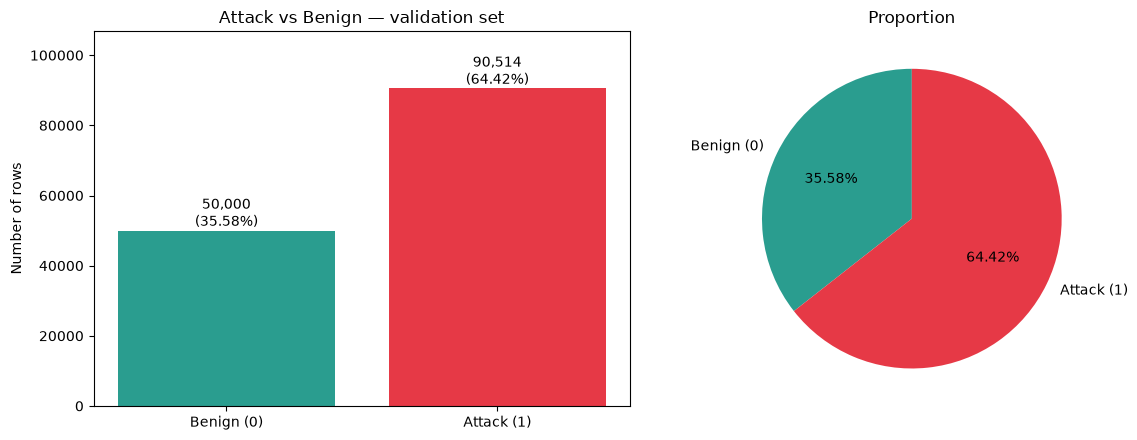

             rows   percent
label                      
Benign (0)  50000 35.580000
Attack (1)  90514 64.420000


In [103]:
counts = df["label"].value_counts().sort_index()
names  = {0: "Benign (0)", 1: "Attack (1)"}
total  = counts.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

bars = ax1.bar([names[i] for i in counts.index], counts.values, color=["#2a9d8f", "#e63946"])
for b, v in zip(bars, counts.values):
    ax1.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/total:.2%})", ha="center", va="bottom")
ax1.set_title("Attack vs Benign — validation set")
ax1.set_ylabel("Number of rows")
ax1.set_ylim(0, counts.max() * 1.18)

ax2.pie(counts.values, labels=[names[i] for i in counts.index], autopct="%1.2f%%",
          colors=["#2a9d8f", "#e63946"], startangle=90)
ax2.set_title("Proportion")
plt.tight_layout()
plt.show()

print(counts.rename(index=names).to_frame("rows").assign(percent=lambda d: (d.rows/total*100).round(2)))

### (Bonus) Distribution of attack classes

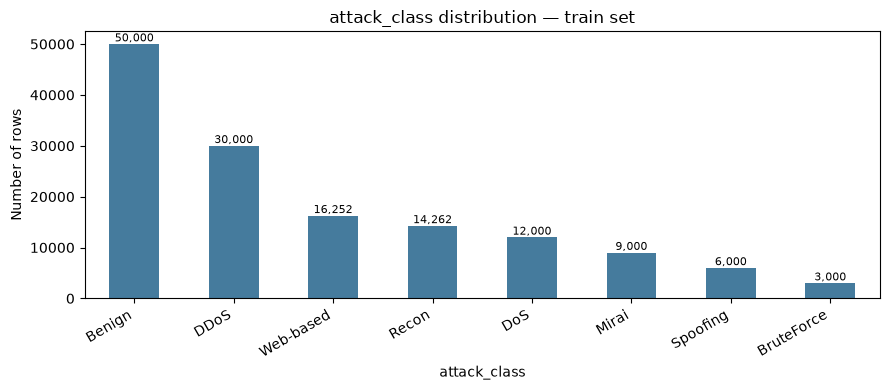

In [104]:
cls = df["attack_class"].value_counts()
plt.figure(figsize=(9, 4))
ax = cls.plot(kind="bar", color="#457b9d")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.title("attack_class distribution — train set")
plt.ylabel("Number of rows"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()